# Lab 1 - Introduction to OpenCV

The notebook mostly shows OpenCV code for image manipulation and processing. Several variants are shown; it is up to you to check them and understand how the OpenCV API is used by referring to the documentation.

The last part is to be done "autonomously", for image classification based on BoW and SVM. A report will be required for this part.

##### Open and show an image:

In [13]:
!pip install opencv-python


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


(225, 224, 3)


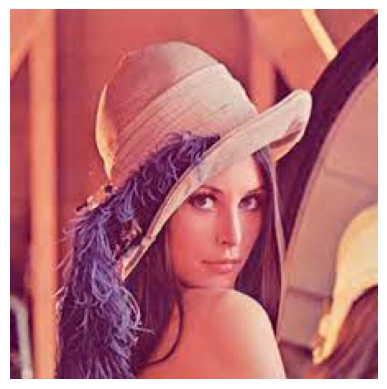

In [7]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('lena.jpeg')

print(img.shape)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [2]:
import cv2 as cv
img = cv.imread("lena.jpeg")

cv.imshow("Display window", img)
k = cv.waitKey(0)

### Some basics image processing:

In [8]:
import cv2
from IPython.display import display, Image

def cv2_imshow(image):
    _, buf = cv2.imencode('.png', image)
    display(Image(data=buf.tobytes()))

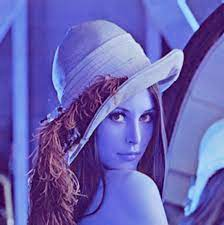

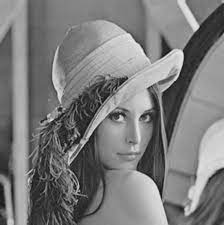

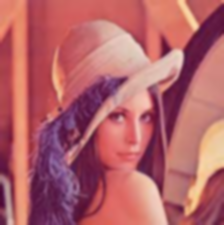

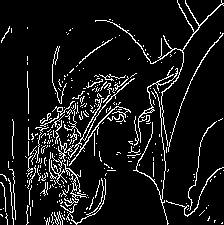

In [9]:
img_RGB = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
cv2_imshow(img_RGB)

img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2_imshow(img_gray)

img_blur = cv2.GaussianBlur(img,(7,7),0) # check what are the arguments
cv2_imshow(img_blur)

img_Canny = cv2.Canny(img,200,200)#100 200
cv2_imshow(img_Canny)

In [ ]:
# Boundary Refinement : Modify object size and shape by shrinking or expanding regions. 
# Noise Reduction: Remove small unwanted regions and improve image quality.

In [42]:
# test 
# 1 is white, 0 is black
mat = np.array([
    [0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0],
], dtype=np.uint8)

# turn the matrix into an image : 1 -> 255 (white), 0 -> 0 (black)
img_test = mat * 255

kernel = np.ones((3, 3), np.uint8)
sep = np.full((img_test.shape[0], 1), 128, dtype=np.uint8) # separating gray column between the two images 
def zoom(image, factor=40):
    return cv2.resize(image, None, fx=factor, fy=factor,
                      interpolation=cv2.INTER_NEAREST)

Before:
 [[0 0 0 0 0 0 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 0 0 0 0 0 0]]
After:
 [[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


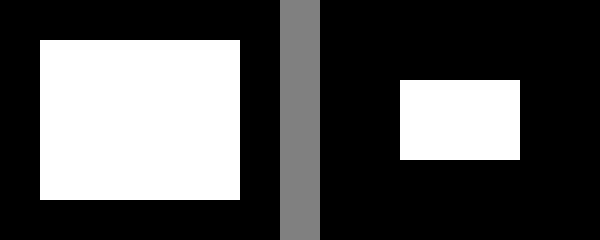

In [43]:
# Erosion : shrinks foreground regions by removing pixels from object boundaries. it "eats" white pixels on the boundaries. With a nxn kernel
#  the white pixel (in the center of the kernel) is kept only if all other pixels are white as well, or else it will turn it black 

eroded = cv2.erode(img_test, kernel, iterations=1)

# Display matrix, before and after 
print("Before:\n", img_test // 255)
print("After:\n", eroded // 255)

# display
images_eroded = np.hstack([img_test, sep, eroded])
cv2_imshow(zoom(images_eroded))

Before:
 [[0 0 0 0 0 0 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 0 0 0 0 0 0]]
After:
 [[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]


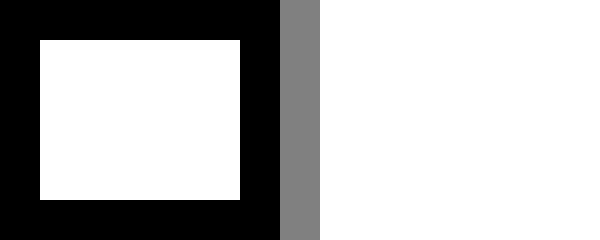

In [44]:
# Dilation : Dilation expands foreground regions by adding pixels to object boundaries

# Dilation with a 3x3 kernel 
dilated = cv2.dilate(img_test, kernel, iterations=1)

# Display matrix, before and after 
print("Before:\n", img_test // 255)
print("After:\n", dilated // 255)

# display
images_dilated = np.hstack([img_test, sep, dilated])
cv2_imshow(zoom(images_dilated))

# the image is now all white

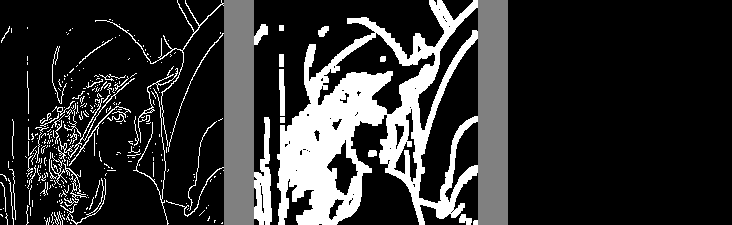

In [38]:
kernel = np.ones((5,5),np.uint8)
img_dilated = cv2.dilate(img_Canny,kernel,iterations = 1)
img_eroded = cv2.erode(img_Canny,kernel,iterations = 1)
sep = np.full((img_Canny.shape[0], 30), 128, dtype=np.uint8)
images = np.hstack([img_Canny, sep, img_dilated, sep, img_eroded])
cv2_imshow(images)

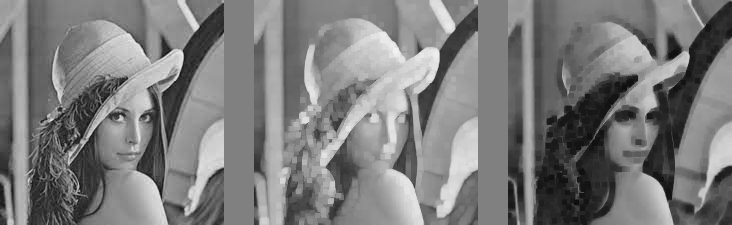

In [39]:
img_dilated_gray = cv2.dilate(img_gray,kernel,iterations = 1)
img_eroded_gray = cv2.erode(img_gray,kernel,iterations = 1)
sep = np.full((img_Canny.shape[0], 30), 128, dtype=np.uint8)
images = np.hstack([img_gray, sep, img_dilated_gray, sep, img_eroded_gray])
cv2_imshow(images)

(225, 224, 3)
(500, 500, 3)


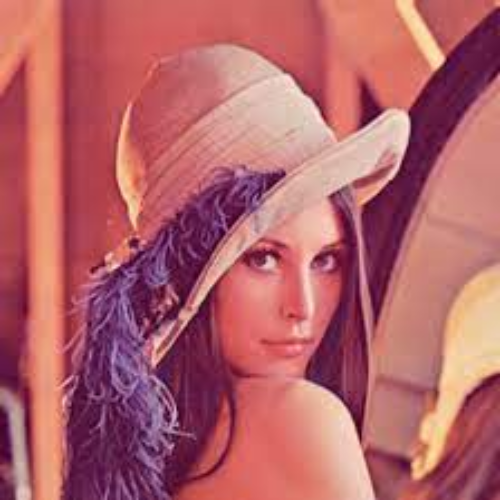

In [46]:
print(img.shape)
img_large = cv2.resize(img,(500,500))
print(img_large.shape)
cv2_imshow(img_large)

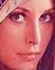

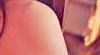

In [55]:
img_crop = img[100:170,100:155]
img_crop_2 = img[170:225,100:200]
cv2_imshow(img_crop)
cv2_imshow(img_crop_2)

(225, 224, 3)
[[255 255 255 255 255]
 [255 255 255 255 255]
 [255 255 255 255 255]
 [255 255 255 255 255]
 [255 255 255 255 255]] [[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]] [[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]


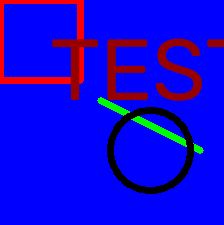

In [74]:
img_blank = np.zeros(img.shape, np.uint8)
print(img_blank.shape)
# image BGR
img_blank[:] = 255,0,0
print(img_blank[:5, :5, 0], img_blank[:5, :5, 1], img_blank[:5, :5, 2])
cv2.line(img_blank,(100,100),(200,150),(0,255,0),5) # (0,255,0) ==> green , 5 = line thickness in pixels 
cv2.rectangle(img_blank,(0,0),(80,80),(0,0,255), 5) # ,cv2.FILLED
cv2.circle(img_blank,(150,150),40,(0,0,0),5)
cv2.putText(img_blank,"TEST!",(50,100),cv2.FONT_HERSHEY_COMPLEX,3,(0,0,150),1) # need the black image's pixel to be np.uint8
# (50,100): bottom-left corner of the text 
cv2_imshow(img_blank)

In [75]:
# Check the image matrix data type (could know the bit depth of the image)
print(img.dtype)
# Check the height of image 
print(img.shape[0])
# Check the width of image 
print(img.shape[1])
# Check the number of channels of the image
print(img.shape[2])


uint8
225
224
3


Number of values (H*W*C) in the image = 151200
image flattened = 151200


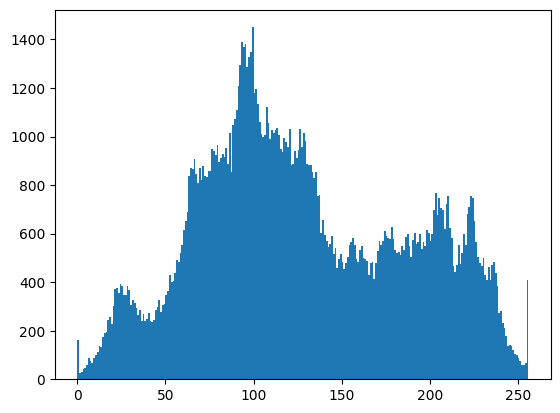

In [80]:
from matplotlib import pyplot as plt
print(f"Number of values (H*W*C) in the image = {img.shape[0]*img.shape[1]*img.shape[2]}")
print(f"image flattened = {len(img.ravel())}")
plt.hist(img.ravel(),bins = 256, range = [0,256]) # check what are arguments
plt.show()

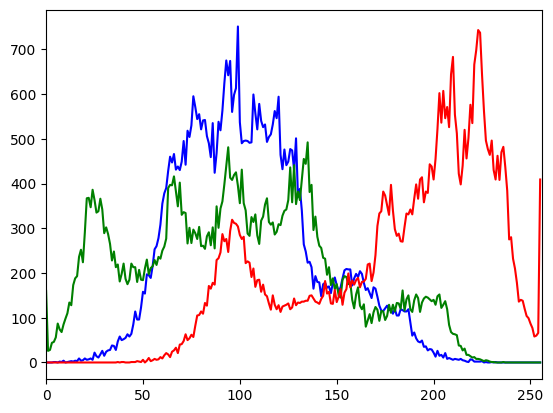

In [81]:
color = ('b','g','r')
for i,col in enumerate(color):
    histr = cv2.calcHist([img],[i],None,[256],[0,256]) # None the mask 
    plt.plot(histr,color = col)
    plt.xlim([0,256])
plt.show()

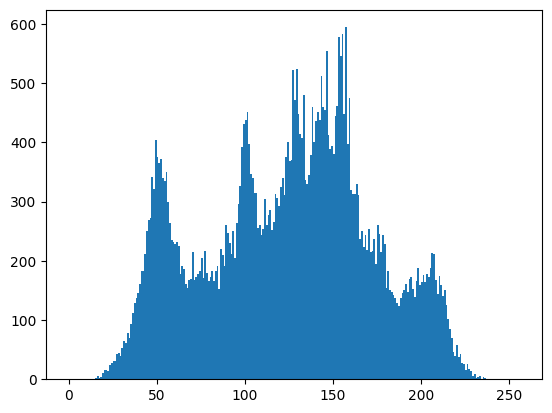

In [82]:
plt.hist(img_gray.ravel(),bins = 256, range = [0, 256])
plt.show()

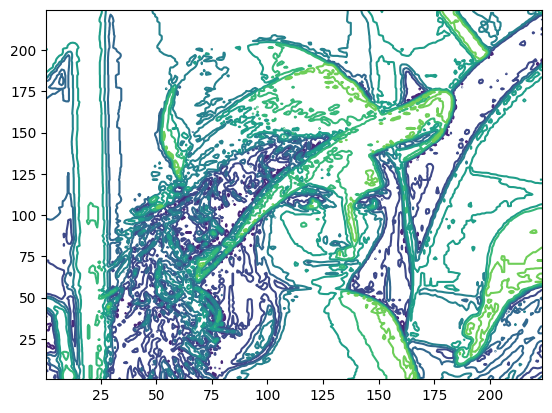

In [83]:
plt.contour(img_gray, origin = "image")

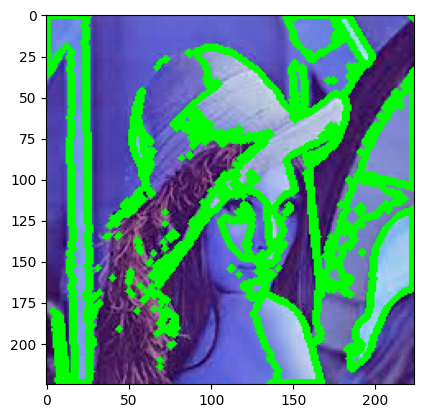

In [85]:
# Set threshold for the contour detection
ret, thresh = cv2.threshold(img_gray,150,255,0) # 0 = cv2.THRESH_BINARY, the type of thresholding 
# pixels > 150 become white (255), all others become 0 (black)
contours, hierarchy = cv2.findContours(thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE) # needs a binary image 
# treats white as the object and black as the background
# thresh is the binary image 
cv2.drawContours(img, contours, -1, (0, 255, 0), 3)
plt.imshow(img)

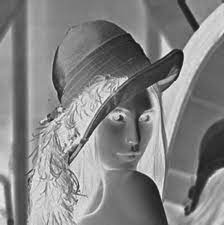

In [86]:
im2 = 255 - img_gray
cv2_imshow(im2)

In [96]:
im3 = (100.0/255)*img_gray + 100
im3_2 = (50.0/255)*img_gray + 100
im3_3 = (200.0/255)*img_gray + 100
sep = np.full((im3.shape[0], 30), 0)
imgs = np.hstack([im3, sep, im3_2, sep, im3_3])
cv2_imshow(zoom(imgs))

im3 = (100.0/255)*img_gray
im3_2 = (50.0/255)*img_gray + 100
im3_3 = (200.0/255)*img_gray + 300
imgs = np.hstack([im3, sep, im3_2, sep, im3_3])
cv2_imshow(zoom(imgs))
# linear intensity transformation, g = alpha*f + beta: contrast and brightness adjustment 
# alpha controls the contrast, beta the brightness

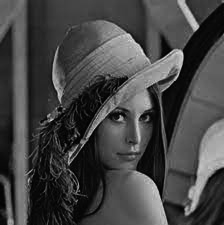

In [97]:
im4 = 255.0*(img_gray/255.0)**2
cv2_imshow(im4)
# an exponent of 2 (> 1) darkens the image

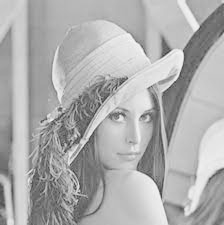

In [99]:
im4 = 255.0*(img_gray/255.0)**0.5
cv2_imshow(im4) # intensities are not all changed in the same way: the transformation is non-linear
# an exponent of 0.5 (< 1) brightens the image 

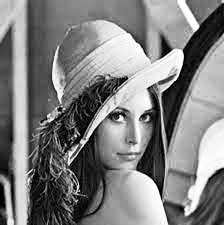

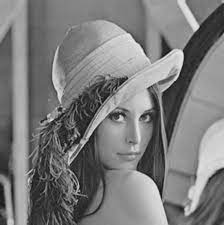

In [100]:
# function for histogram equalization
def histeq(im, nbr_bins = 256):
  """ Histogram equalization of a grayscale image.  """
  # get the image histogram
  imhist, bins = np.histogram(im.flatten(), nbr_bins, [0, 256])
  cdf = imhist.cumsum() # cumulative distribution function
  cdf = imhist.max()*cdf/cdf.max()  #normalize
  cdf_mask = np.ma.masked_equal(cdf, 0)
  cdf_mask = (cdf_mask - cdf_mask.min())*255/(cdf_mask.max()-cdf_mask.min())
  cdf = np.ma.filled(cdf_mask,0).astype('uint8')
  return cdf[im.astype('uint8')]

# apply the function on your dark image to increase the contrast
# we could observe that the contrast of the black background has increased
im5 = histeq(img_gray)
cv2_imshow(im5)
cv2_imshow(img_gray)

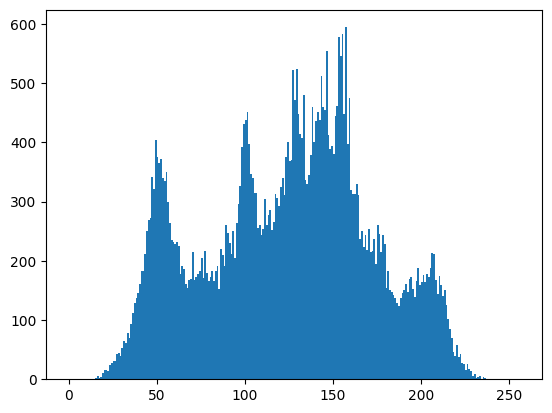

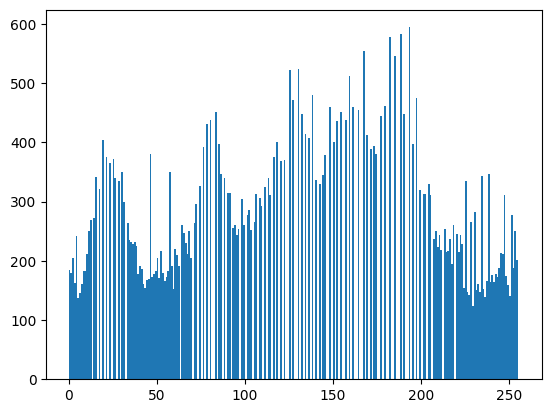

In [101]:
plt.hist(img_gray.ravel(),bins = 256, range = [0, 256])
plt.show()
plt.hist(im5.ravel(),bins = 256, range = [0, 256])
plt.show()

### Keypoints detection and local descriptors:

In [ ]:
# A keypoint is a point in the image that can be reliably and repeatably located, meaning it has a distinctive local structure. 
# Good keypoints are:
# - Corners (intersections of two edges)
# - Blobs (small bright or dark spots)
# - Regions with strong intensity changes in multiple directions
# Uniform areas (a blue sky) and straight edges make poor keypoints: 
# along an edge you cannot tell exactly where you are, since every position looks the same

315 (315, 128)
166 (166, 128)
418 (418, 128)


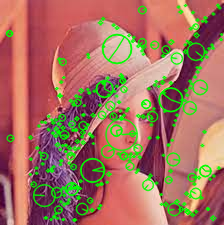

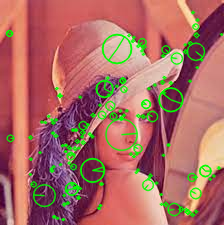

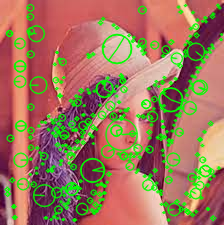

In [113]:
detector_1 = cv2.SIFT_create(nfeatures=0, nOctaveLayers=3, contrastThreshold=0.04, edgeThreshold=10, sigma=1.6)
detector_2 = cv2.SIFT_create(nfeatures=0, nOctaveLayers=3, contrastThreshold=0.08, edgeThreshold=10, sigma=1.6) # fewer low-contrast points
detector_3 = cv2.SIFT_create(nfeatures=0, nOctaveLayers=3, contrastThreshold=0.04, edgeThreshold=100, sigma=1.6) # more keypoints on edges

keypoints_1, descriptors_1 = detector_1.detectAndCompute(img_gray, None)
keypoints_2, descriptors_2 = detector_2.detectAndCompute(img_gray, None)
keypoints_3, descriptors_3 = detector_3.detectAndCompute(img_gray, None)

print(len(keypoints_1), descriptors_1.shape)   # (n, 128)
print(len(keypoints_2), descriptors_2.shape)
print(len(keypoints_3), descriptors_3.shape)

img_keypoints_1 = cv2.drawKeypoints(
    img, keypoints_1, None, color=(0, 255, 0),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

img_keypoints_2 = cv2.drawKeypoints(
    img, keypoints_2, None, color=(0, 255, 0),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

img_keypoints_3 = cv2.drawKeypoints(
    img, keypoints_3, None, color=(0, 255, 0),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)


cv2_imshow(img_keypoints_1)
cv2_imshow(img_keypoints_2)
cv2_imshow(img_keypoints_3)

In [114]:
print(descriptors_1[0])

[  0.   0.   0.   1.  32. 155.   0.   0.  27.   0.   0.   1.   6.  60.
   5.  30.  38.   0.   0.   0.   0.   0.   0.  32.   0.   0.   0.   0.
   0.   0.   0.   0.   4.  25.   0.   0.  16. 155.   2.   0.  80.   3.
   0.   0.  16. 155.  17.  23. 155.  25.   0.   0.   0.  11.   7.  44.
  21.   5.   1.   0.   0.   0.   0.   2.  26. 155.   0.   0.   5.  62.
   1.   0.  16.  20.   0.   0.  19. 155.  34.  12. 155.  17.   0.   0.
   0.  52.  46.  66.  40.   9.   1.   3.   4.   0.   0.   5.  41. 155.
   0.   0.   0.   3.   0.   0.  16. 152.   2.   0.   3.  45.  11.   1.
  17.   9.   1.   0.   1.  25.  33.  43.   8.   0.   0.   5.  16.   1.
   1.  12.]


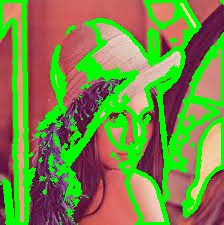

In [105]:
gray_img = np.float32(img_gray)

dst = cv2.cornerHarris(gray_img, blockSize=2, ksize=3, k=0.04)

# Mark the corners
img[dst > 0.01 * dst.max()] = [0, 255, 0]

cv2_imshow(img)

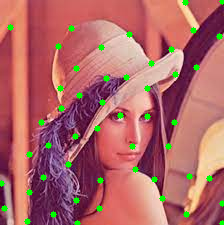

In [11]:
corners = cv2.goodFeaturesToTrack(img_gray, maxCorners=50, qualityLevel=0.02, minDistance=20)
# corner detection only 
corners = np.float32(corners)

img = cv2.imread('lena.jpeg')
for item in corners:
    x, y = item[0]
    cv2.circle(img, (int(x), int(y)), 3, (0, 255, 0), -1)

cv2_imshow(img)

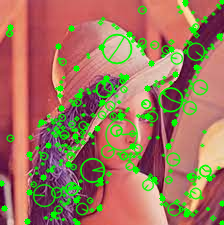

In [14]:
sift = cv2.SIFT_create()
kp, des = sift.detectAndCompute(img_gray, None)

kp_img = cv2.drawKeypoints(img, kp, None, color=(0, 255, 0),                    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
cv2_imshow(kp_img)

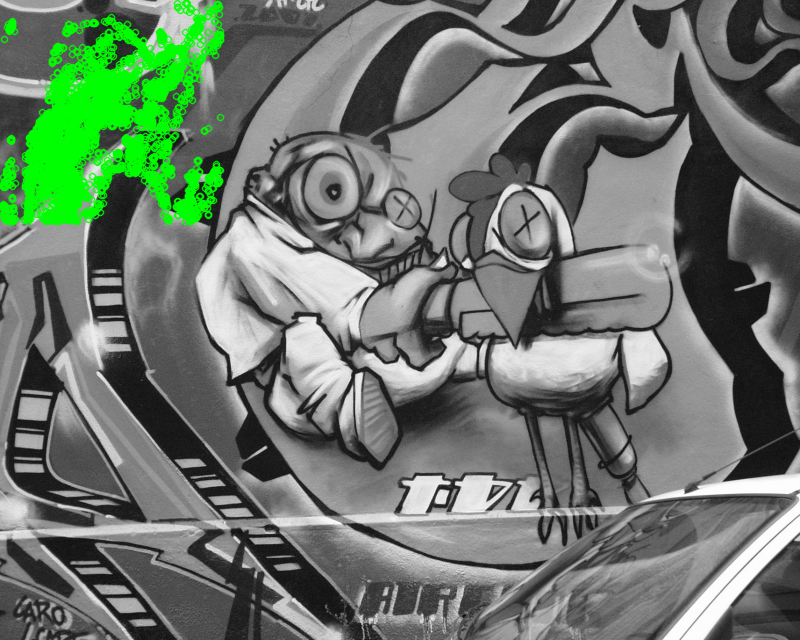

In [21]:
fast = cv2.FastFeatureDetector_create()
fast.setNonmaxSuppression(False)

kp = fast.detect(img_gray, None)
kp_img = cv2.drawKeypoints(img, kp, None, color=(0, 255, 0))

cv2_imshow(kp_img)

"""
This code uses FAST (Features from Accelerated Segment Test), a keypoint detection algorithm. 
It is particularly interesting because it is designed to be very fast, 
especially for real-time applications.
Unlike SIFT, FAST essentially detects corners, without computing descriptors.
Consider a candidate pixel p.
We examine the 16 pixels on a circle around it.
We compare their intensity with that of the central pixel.
If enough consecutive pixels are significantly brighter or darker than the central pixel, 
it is considered a corner.
"""

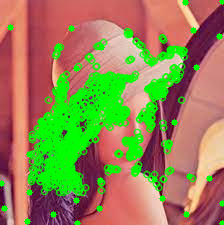

In [16]:
orb = cv2.ORB_create(nfeatures=2000)
kp, des = orb.detectAndCompute(img_gray, None)

kp_img = cv2.drawKeypoints(img, kp, None, color=(0, 255, 0), flags=0)

cv2_imshow(kp_img)

"""
This code uses ORB (Oriented FAST and Rotated BRIEF), an algorithm that combines two ideas:
- FAST to detect keypoints.
- BRIEF to compute a descriptor for each point, with an adaptation to handle rotations.
ORB was designed as a fast, free alternative to SIFT and SURF.
"""

### Using local descriptors for images matching:

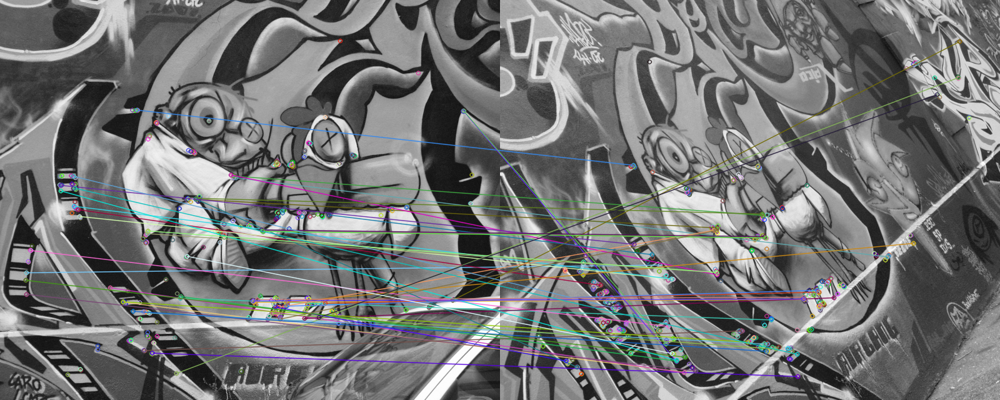

In [23]:
img1 = cv2.imread('img1.ppm', 0)
img2 = cv2.imread('img4.ppm', 0)

orb = cv2.ORB_create(nfeatures=500)
kp1, des1 = orb.detectAndCompute(img1, None)
kp2, des2 = orb.detectAndCompute(img2, None)

# matcher takes normType, which is set to cv2.NORM_L2 for SIFT and SURF, cv2.NORM_HAMMING for ORB, FAST and BRIEF
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda x: x.distance)# draw first 50 matches
match_img = cv2.drawMatches(img1, kp1, img2, kp2, matches[:50], None)
cv2_imshow(match_img)

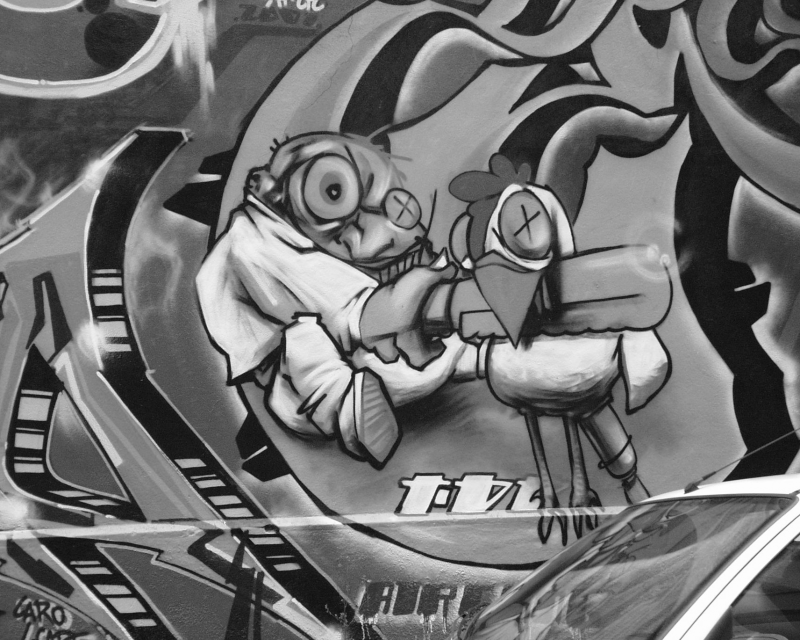

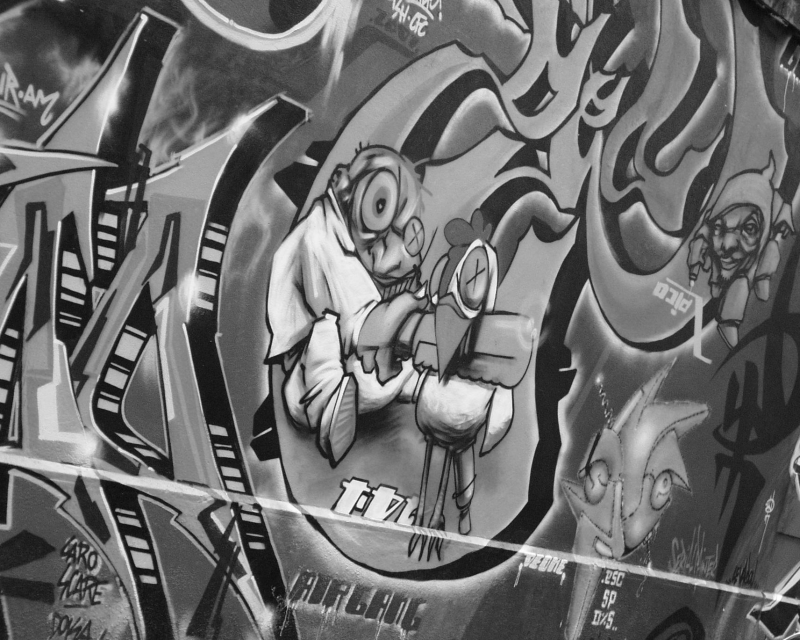

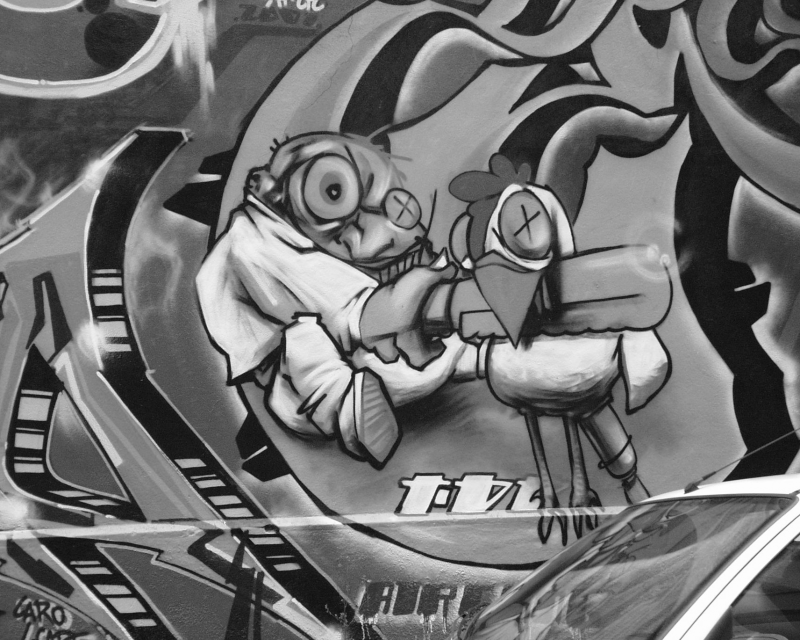

In [18]:
def get_corrected_img(img1, img2):
    MIN_MATCHES = 50

    orb = cv2.ORB_create(nfeatures=500)
    kp1, des1 = orb.detectAndCompute(img1, None)
    kp2, des2 = orb.detectAndCompute(img2, None)

    index_params = dict(algorithm=6,
                        table_number=6,
                        key_size=12,
                        multi_probe_level=2)
    search_params = {}
    flann = cv2.FlannBasedMatcher(index_params, search_params)
    matches = flann.knnMatch(des1, des2, k=2)

    # As per Lowe's ratio test to filter good matches
    good_matches = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

    if len(good_matches) > MIN_MATCHES:
        src_points = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        dst_points = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        m, mask = cv2.findHomography(src_points, dst_points, cv2.RANSAC, 5.0)
        corrected_img = cv2.warpPerspective(img1, m, (img2.shape[1], img2.shape[0]))

        return corrected_img
    return img2


img1 = cv2.imread('img1.ppm', 0)
img2 = cv2.imread('img3.ppm', 0)
img = get_corrected_img(img2, img1)
cv2_imshow(img1)
cv2_imshow(img2)
cv2_imshow(img)

### Image convolution:

In [19]:
# Custom implementation of 2D convolution
def convolve2D(image, kernel, padding=0, strides=1):
    # Cross Correlation
    kernel = np.flipud(np.fliplr(kernel))

    # Gather Shapes of Kernel + Image + Padding
    xKernShape = kernel.shape[0]
    yKernShape = kernel.shape[1]
    xImgShape = image.shape[0]
    yImgShape = image.shape[1]

    # Shape of Output Convolution
    xOutput = int(((xImgShape - xKernShape + 2 * padding) / strides) + 1)
    yOutput = int(((yImgShape - yKernShape + 2 * padding) / strides) + 1)
    output = np.zeros((xOutput, yOutput))

    # Apply Equal Padding to All Sides
    if padding != 0:
        imagePadded = np.zeros((image.shape[0] + padding*2, image.shape[1] + padding*2))
        imagePadded[int(padding):int(-1 * padding), int(padding):int(-1 * padding)] = image
        #print(imagePadded)
    else:
        imagePadded = image

    # Iterate through image
    for y in range(image.shape[1]):
        # Exit Convolution
        if y > image.shape[1] - yKernShape:
            break
        # Only Convolve if y has gone down by the specified Strides
        if y % strides == 0:
            for x in range(image.shape[0]):
                # Go to next row once kernel is out of bounds
                if x > image.shape[0] - xKernShape:
                    break
                try:
                    # Only Convolve if x has moved by the specified Strides
                    if x % strides == 0:
                        output[x, y] = (kernel * imagePadded[x: x + xKernShape, y: y + yKernShape]).sum()
                except:
                    break

    return output

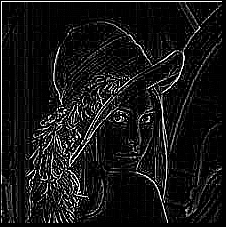

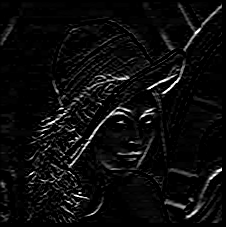

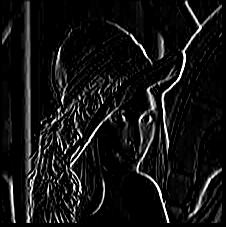

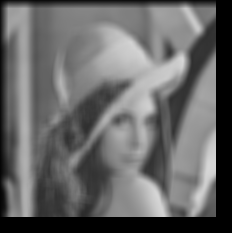

In [20]:
kernel = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]])
kernel2 = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]])
kernel3 = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])

kernel4 = np.ones((9,9)) /81

output = convolve2D(img_gray, kernel, padding=2)
cv2_imshow(output)

output = convolve2D(img_gray, kernel2, padding=2)
cv2_imshow(output)

output = convolve2D(img_gray, kernel3, padding=2)
cv2_imshow(output)

output = convolve2D(img_gray, kernel4, padding=8)
cv2_imshow(output)

### TODO: Feature encoding / BOW descriptors

- Load images dataset from next cell. There are 2000 images among 4 classes of animals. 1500 images are for training, 500 for evaluation.

- Use SIFT, SURF or equivalent to get local features on every images of the dataset, cluster the training features into 200 clusters using K-means (from sklearn)

- Compute BOW descriptors (histogram of 200 bins..) for each images in training and testing sets. L2 normalize the descriptors.

- Learn rbf SVM and evaluate the classification performance and test set

- Try others descriptors, variate the codebook size, ...


In [25]:
import requests

base_url = "https://pageperso.lis-lab.fr/stephane.ayache/TP_transfer/"

files = [
    "imagenetXtrain.npy",
    "imagenetYtrain.npy",
    "imagenetXtest.npy",
    "imagenetYtest.npy"
]

for filename in files:
    response = requests.get(base_url + filename)
    response.raise_for_status()

    with open(filename, "wb") as f:
        f.write(response.content)

    print(f"{filename} downloaded!")

imagenetXtrain.npy downloaded!
imagenetYtrain.npy downloaded!
imagenetXtest.npy downloaded!
imagenetYtest.npy downloaded!


In [52]:
# imports 
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [29]:
# 1. Load the data 
X_train = np.load("imagenetXtrain.npy", allow_pickle=True)
y_train = np.load("imagenetYtrain.npy", allow_pickle=True)

X_test = np.load("imagenetXtest.npy", allow_pickle=True)
y_test = np.load("imagenetYtest.npy", allow_pickle=True)

train : 1500 images | test : 500 images
shape of one image: (64, 64, 3) | type : uint8
train classes: (array([0, 1, 2, 3]), array([381, 367, 372, 380]))
test classes : (array([0, 1, 2, 3]), array([119, 133, 128, 120]))


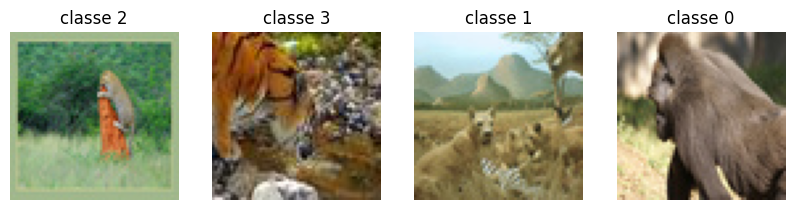

In [33]:
# 2. Dataset check
print("train :", len(X_train), "images | test :", len(X_test), "images")
print("shape of one image:", X_train[0].shape, "| type :", X_train[0].dtype)
print("train classes:", np.unique(y_train, return_counts=True))
print("test classes :", np.unique(y_test, return_counts=True))

plt.figure(figsize=(10, 3))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(X_train[i])        
    plt.title(f"class {y_train[i]}"); plt.axis('off')
plt.show()

## **3. Local feature extraction (SIFT)**
For each image:
1. conversion to grayscale (SIFT works on intensity);
2. keypoint detection and computation of a 128-value descriptor per point.

Each image therefore yields a matrix (n_points, 128), with a **variable n_points** depending on the image.
If no point is detected, SIFT returns `None`: we replace it with an empty matrix to avoid an error.

In [36]:
sift = cv2.SIFT_create()

def extract_sift(images):
    """Returns a list of arrays (n_i, 128), one per image."""
    results = []
    for img in images:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) if img.ndim == 3 else img # check whether the image is already grayscale
        _, desc = sift.detectAndCompute(gray, None)
        results.append(desc if desc is not None else np.zeros((0, 128), np.float32))
    return results

desc_train = extract_sift(X_train)
desc_test  = extract_sift(X_test)

## **4. Descriptor statistics**
We check the number of points per image and the total number of training descriptors.
This justifies the need for Bag of Visual Words: the number of descriptors varies from one image to another,
whereas the SVM requires a fixed-size vector.

points per image: min=0, mean=47, max=118
images with no keypoints: 1
total training descriptors: 69876


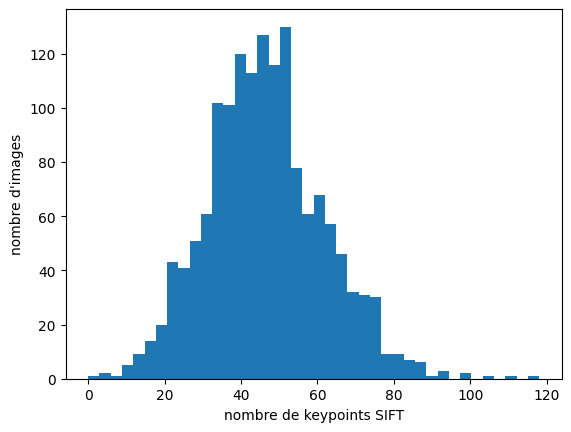

In [39]:
n_points = np.array([len(d) for d in desc_train])
print(f"points per image: min={n_points.min()}, mean={n_points.mean():.0f}, max={n_points.max()}")
print("images with no keypoints:", (n_points == 0).sum())
print("total training descriptors:", n_points.sum())

plt.hist(n_points, bins=40)
plt.xlabel("number of SIFT keypoints"); plt.ylabel("number of images")
plt.show()

## **5. Building the codebook (K-means)**
We stack the SIFT descriptors of **all training images** and group them into K = 200 clusters.
Each cluster center is a **visual word** that would represent a typical local pattern such as corners or textures.

In [40]:
K = 200

stacked_desc = np.vstack(desc_train)

kmeans = KMeans(n_clusters=K, n_init=3, random_state=0)
kmeans.fit(stacked_desc)

print("Number of descriptors:", len(stacked_desc))
print("Codebook :", kmeans.cluster_centers_.shape)

Number of descriptors: 69876
Codebook : (200, 128)


## **6. Bag of Visual Words descriptors**
For each image:
1. each SIFT descriptor is assigned to the **closest visual word** ('kmeans.predict'), 
2. we count how many descriptors fall into each of the 200 words: a histogram of 200 values, 
3. we apply an **L2 normalization**, so that images with many or few points are comparable.

(1500, 200) (500, 200)
L2 norm: 1.0


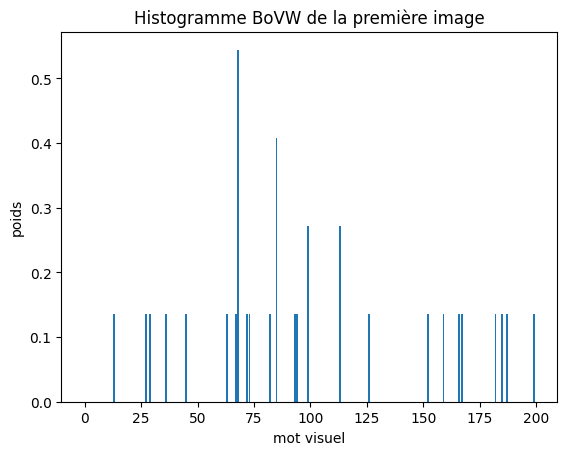

In [41]:
def bovw(desc_list, kmeans, K):
    H = np.zeros((len(desc_list), K), np.float32)
    for i, d in enumerate(desc_list):
        if len(d) > 0:
            words = kmeans.predict(d.astype(np.float32))
            H[i] = np.bincount(words, minlength=K)
    return normalize(H, norm='l2')

H_train = bovw(desc_train, kmeans, K)
H_test  = bovw(desc_test,  kmeans, K)

print(H_train.shape, H_test.shape)               
print("L2 norm:", np.linalg.norm(H_train[0]))    # = 1 (except for an image with no keypoints)

plt.bar(range(K), H_train[0]); plt.xlabel("visual word"); plt.ylabel("weight")
plt.title("BoVW histogram of the first image"); plt.show()

## **7. Classification with an RBF-kernel SVM**
The SVM is trained on the training histograms, then evaluated on the test set.
Hyperparameters are tuned with Grid Search and cross-validation.

In [44]:
clf = SVC(kernel='rbf', C=10, gamma=0.1)
# high gamma values: more complex decision boundary 
clf.fit(H_train, y_train)

pred = clf.predict(H_test)
print("accuracy train :", accuracy_score(y_train, clf.predict(H_train)))
print("accuracy test  :", accuracy_score(y_test, pred))

accuracy train : 0.6853333333333333
accuracy test  : 0.41


In [48]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100, 1000],
    'gamma': [0.0001, 0.001, 0.01, 0.1, 1, 10]
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=SVC(kernel='rbf'),
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv,
    n_jobs=-2,
    verbose=2,
    return_train_score=True
)
grid.fit(H_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,estimator,SVC()
,param_grid,"{'C': [0.01, 0.1, ...], 'gamma': [0.0001, 0.001, ...]}"
,scoring,'accuracy'
,n_jobs,-2
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,C,1


In [53]:
print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", grid.best_score_)
best_clf = grid.best_estimator_
best_idx = grid.best_index_

Best parameters: {'C': 1, 'gamma': 1}
Best CV accuracy: 0.45666666666666667


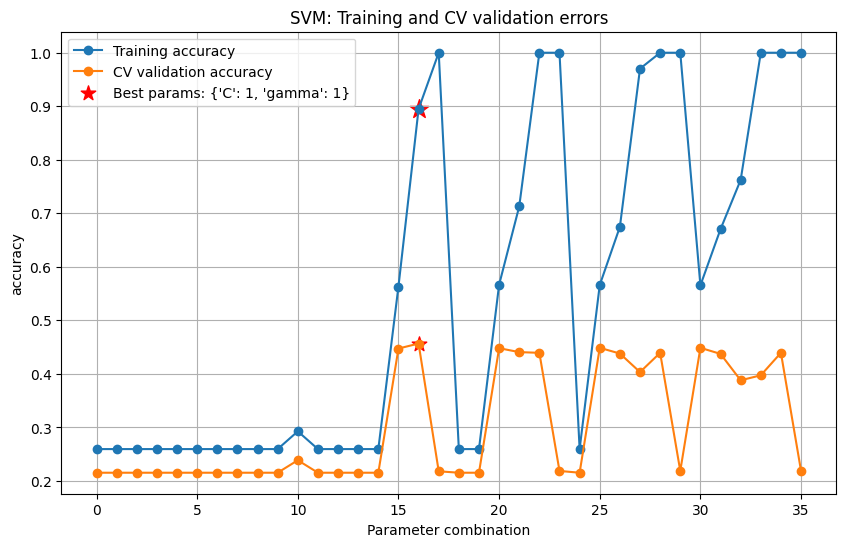

In [57]:
results = pd.DataFrame(grid.cv_results_)

train_score = results['mean_train_score']
val_score = results['mean_test_score']

plt.figure(figsize=(10, 6))

plt.plot(train_error.values, label='Training accuracy', marker='o')
plt.plot(val_error.values, label='CV validation accuracy', marker='o')

plt.scatter(best_idx, val_score.iloc[best_idx], color='red', s=120, marker='*',
            label=f'Best params: {grid.best_params_}')
plt.scatter(best_idx, train_score.iloc[best_idx], color='red', s=200, marker='*')

plt.xlabel('Parameter combination')
plt.ylabel('accuracy')
plt.title('SVM: Training and CV validation errors')
plt.legend()
plt.grid()
plt.show()

## **8. Error analysis with a confusion matrix**

In [60]:
# train our best model
clf = SVC(kernel='rbf', C=1, gamma=1)
clf.fit(H_train, y_train)

pred = clf.predict(H_test)
print("accuracy train :", accuracy_score(y_train, clf.predict(H_train)))
print("accuracy test  :", accuracy_score(y_test, pred))

accuracy train : 0.8766666666666667
accuracy test  : 0.468


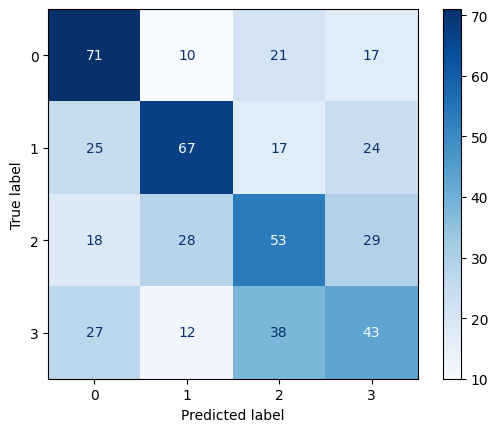

In [61]:
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm).plot(cmap='Blues')
plt.show()

## **10. Influence of the codebook size K**
We repeat the whole pipeline (K-means, BoVW, SVM) for several values of K.

In [62]:
C = 1; gamma = 1

K=   50 : test accuracy = 0.446
K=  100 : test accuracy = 0.492
K=  200 : test accuracy = 0.454
K=  500 : test accuracy = 0.482
K= 1000 : test accuracy = 0.472


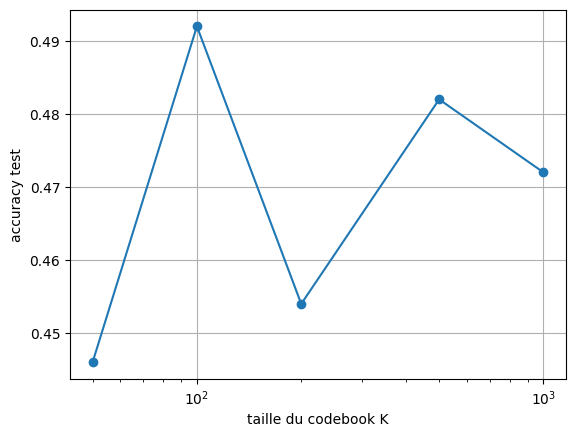

In [64]:
results = {}
for k in [50, 100, 200, 500, 1000]:
    km = KMeans(n_clusters=k, n_init=3, random_state=42).fit(stacked_desc)
    H_train, H_test = bovw(desc_train, km, k), bovw(desc_test, km, k)
    acc = accuracy_score(y_test, SVC(kernel='rbf', C=C, gamma=gamma).fit(H_train, y_train).predict(H_test))
    results[k] = acc
    print(f"K={k:5d} : test accuracy = {acc:.3f}")

plt.plot(list(results), list(results.values()), 'o-')
plt.xscale('log'); plt.xlabel("codebook size K"); plt.ylabel("test accuracy"); plt.grid()
plt.show()

In [66]:
# reuse the same grid 
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100, 1000],
    'gamma': [0.0001, 0.001, 0.01, 0.1, 1, 10]
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = {}
for k in [50, 100, 500, 1000]:                  
    km = KMeans(n_clusters=k, n_init=3, random_state=42).fit(stacked_desc)
    H_train, H_test = bovw(desc_train, km, k), bovw(desc_test, km, k)

    gs = GridSearchCV(SVC(kernel='rbf'), param_grid, scoring='accuracy', cv=cv, n_jobs=-2).fit(H_train, y_train)
    results[k] = {"cv": gs.best_score_,
                    "test": gs.score(H_test, y_test),
                    "params": gs.best_params_}
    print(f"K={k:5d} | CV = {results[k]['cv']:.3f} "
          f"| test = {results[k]['test']:.3f} | {gs.best_params_}")


K=   50 | CV = 0.448 | test = 0.446 | {'C': 1, 'gamma': 1}
K=  100 | CV = 0.461 | test = 0.492 | {'C': 1, 'gamma': 1}
K=  500 | CV = 0.423 | test = 0.482 | {'C': 1, 'gamma': 1}
K= 1000 | CV = 0.431 | test = 0.472 | {'C': 1, 'gamma': 1}


## **11. Other variations**

### **ORB: local feature extraction**

In [72]:
orb = cv2.ORB_create(nfeatures=1000, scaleFactor=1.2, nlevels=8,
                     edgeThreshold=15, patchSize=15, fastThreshold=10)

def extract_orb(images):
    """Returns a list of arrays (n_i, 128), one per image."""
    results = []
    for img in images:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) if img.ndim == 3 else img # check whether the image is already grayscale
        _, desc = orb.detectAndCompute(gray, None)
        results.append(desc if desc is not None else np.zeros((0, 128), np.float32))
    return results

desc_train = extract_orb(X_train)
desc_test  = extract_orb(X_test)

points per image: min=24, mean=127, max=191
images with no keypoints: 0
total training descriptors: 190935


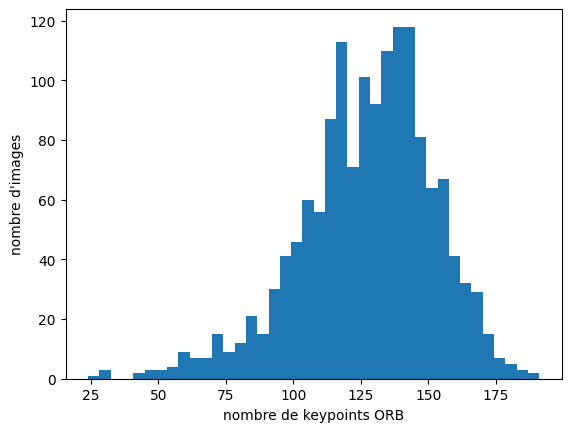

In [73]:
n_points = np.array([len(d) for d in desc_train])
print(f"points per image: min={n_points.min()}, mean={n_points.mean():.0f}, max={n_points.max()}")
print("images with no keypoints:", (n_points == 0).sum())
print("total training descriptors:", n_points.sum())

plt.hist(n_points, bins=40)
plt.xlabel("number of ORB keypoints"); plt.ylabel("number of images")
plt.show()

In [75]:
def bits(d):
    return np.unpackbits(d, axis=1).astype(np.float32)   # (n, 32) -> (n, 256)

K = 200
stacked_desc = bits(np.vstack(desc_train))

kmeans = KMeans(n_clusters=K, n_init=3, random_state=0)
kmeans.fit(stacked_desc)

print("Number of descriptors:", len(stacked_desc))
print("Codebook :", kmeans.cluster_centers_.shape)

Number of descriptors: 190935
Codebook : (200, 256)


(1500, 200) (500, 200)
L2 norm: 1.0


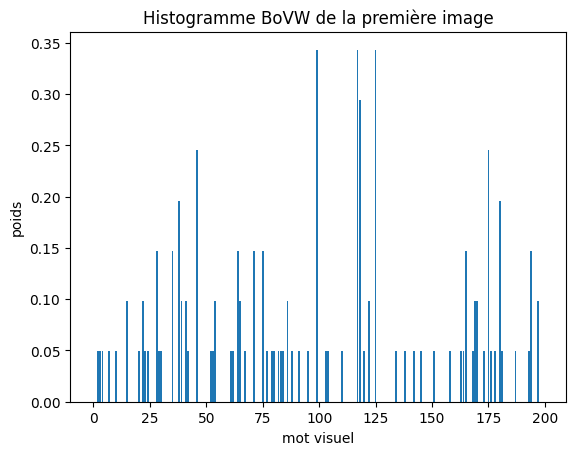

In [76]:
def bovw_orb(desc_list, kmeans, K):
    H = np.zeros((len(desc_list), K), np.float32)
    for i, d in enumerate(desc_list):
        if len(d) > 0:
            words = kmeans.predict(bits(d))
            H[i] = np.bincount(words, minlength=K)
    return normalize(H, norm='l2')

H_train_orb = bovw_orb(desc_train, kmeans, K)
H_test_orb  = bovw_orb(desc_test,  kmeans, K)

print(H_train_orb.shape, H_test_orb.shape)                 
print("L2 norm:", np.linalg.norm(H_train_orb[0]))   

plt.bar(range(K), H_train_orb[0]); plt.xlabel("visual word"); plt.ylabel("weight")
plt.title("BoVW histogram of the first image"); plt.show()

In [77]:
clf = SVC(kernel='rbf', C=1, gamma=1)
clf.fit(H_train_orb, y_train)

pred = clf.predict(H_test_orb)
print("accuracy train :", accuracy_score(y_train, clf.predict(H_train_orb)))
print("accuracy test  :", accuracy_score(y_test, pred))

accuracy train : 0.7646666666666667
accuracy test  : 0.372


In [79]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100, 1000],
    'gamma': [0.0001, 0.001, 0.01, 0.1, 1, 10]
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid_orb = GridSearchCV(
    estimator=SVC(kernel='rbf'),
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv,
    n_jobs=-2,
    verbose=2,
    return_train_score=True
)
grid_orb.fit(H_train_orb, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,estimator,SVC()
,param_grid,"{'C': [0.01, 0.1, ...], 'gamma': [0.0001, 0.001, ...]}"
,scoring,'accuracy'
,n_jobs,-2
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,C,1


In [80]:
pred_orb = grid_orb.predict(H_test_orb)
print("best parameters :", grid_orb.best_params_)
print("CV accuracy     :", grid_orb.best_score_)
print("test accuracy   :", accuracy_score(y_test, pred_orb))

best parameters : {'C': 1, 'gamma': 1}
CV accuracy     : 0.35533333333333333
test accuracy   : 0.372


In [81]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = {}
for k in [50, 100, 500, 1000]:                  
    km = KMeans(n_clusters=k, n_init=1, random_state=42).fit(stacked_desc) # set n_init to 1 to save training time
    H_train_orb, H_test_orb = bovw_orb(desc_train, km, k), bovw_orb(desc_test, km, k) 

    gs = GridSearchCV(SVC(kernel='rbf'), param_grid, scoring='accuracy', cv=cv, n_jobs=-2).fit(H_train_orb, y_train)
    results[k] = {"cv": gs.best_score_,
                    "test": gs.score(H_test_orb, y_test),
                    "params": gs.best_params_}
    print(f"K={k:5d} | CV = {results[k]['cv']:.3f} "
          f"| test = {results[k]['test']:.3f} | {gs.best_params_}")

K=   50 | CV = 0.375 | test = 0.372 | {'C': 1, 'gamma': 1}
K=  100 | CV = 0.357 | test = 0.358 | {'C': 1, 'gamma': 1}


C:\Users\slima\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


K=  500 | CV = 0.379 | test = 0.372 | {'C': 10, 'gamma': 1}
K= 1000 | CV = 0.375 | test = 0.380 | {'C': 1, 'gamma': 1}
